In [ ]:
#NAME: SUSHIL KUMAR
#ADM NO: 2026B15310463
#BRAMCH: AIML6
#GROUP:  07
#TITLE: Climate Extreme & Regional Trend Analysis

In [1]:
from google.colab import files
uploaded = files.upload()   # Upload climate_data.csv

Saving climate_data.csv to climate_data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('climate_data.csv')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

print('Rows:', len(df))
print('Regions:', df['region'].unique())
print('Units: temperature in °C, rainfall in mm per month')
display(df.head())

Rows: 356
Regions: ['Coast' 'North' 'South']
Units: temperature in °C, rainfall in mm per month


,date,region,station_id,temperature_c,rainfall_mm,year,month
0,2015-01-01,Coast,C001,25.0,38.6,2015,1
1,2015-02-01,Coast,C001,27.0,70.7,2015,2
2,2015-03-01,Coast,C001,28.7,114.8,2015,3
3,2015-04-01,Coast,C001,29.9,73.3,2015,4
4,2015-05-01,Coast,C001,28.8,59.0,2015,5


In [3]:
print('Missing values:')
print(df.isnull().sum())
print('Duplicate station-month rows:', df.duplicated(['station_id', 'date']).sum())
print('Start:', df['date'].min().date(), '| End:', df['date'].max().date())

# Check if a region used more than one station ID.
print('Station IDs per region:')
print(df.groupby('region')['station_id'].nunique())

# Expected = 12 months each year for each region.
for region in df['region'].unique():
    actual = set(df.loc[df['region'] == region, 'date'])
    expected = set(pd.date_range('2015-01-01', '2024-12-01', freq='MS'))
    missing_months = sorted(expected - actual)
    print(region, '- missing months:', [d.strftime('%Y-%m') for d in missing_months])

# Missing months are NOT filled or guessed.

Missing values:
date             0
region           0
station_id       0
temperature_c    0
rainfall_mm      0
year             0
month            0
dtype: int64
Duplicate station-month rows: 0
Start: 2015-01-01 | End: 2024-12-01
Station IDs per region:
region
Coast    1
North    1
South    1
Name: station_id, dtype: int64
Coast - missing months: ['2016-04', '2023-10']
North - missing months: ['2017-08']
South - missing months: ['2020-02']


In [4]:
baseline = df[df['year'].between(2015, 2019)]
normal_temp = baseline.groupby(['region', 'month'])['temperature_c'].mean()

df['normal_temp'] = df.set_index(['region', 'month']).index.map(normal_temp)
df['temp_anomaly'] = df['temperature_c'] - df['normal_temp']

display(df[['date', 'region', 'temperature_c', 'normal_temp', 'temp_anomaly']].head())

,date,region,temperature_c,normal_temp,temp_anomaly
0,2015-01-01,Coast,25.0,26.160,-1.160
1,2015-02-01,Coast,27.0,27.180,-0.180
2,2015-03-01,Coast,28.7,28.600,0.100
3,2015-04-01,Coast,29.9,29.625,0.275
4,2015-05-01,Coast,28.8,29.640,-0.840


In [5]:
df['hot_month'] = df['temperature_c'] >= 32
df['wet_month'] = df['rainfall_mm'] >= 200

print('Total hot months:', df['hot_month'].sum())
print('Total wet months:', df['wet_month'].sum())
print('Temperature 90th percentile:', round(np.percentile(df['temperature_c'], 90), 2))
print('Rainfall 90th percentile:', round(np.percentile(df['rainfall_mm'], 90), 2))

summary = df.groupby('region').agg(
    avg_temp=('temperature_c', 'mean'),
    avg_rain=('rainfall_mm', 'mean'),
    hot_months=('hot_month', 'sum'),
    wet_months=('wet_month', 'sum')
).round(2)
display(summary)

Total hot months: 28
Total wet months: 54
Temperature 90th percentile: 31.45
Rainfall 90th percentile: 221.75


,avg_temp,avg_rain,hot_months,wet_months
region,,,,
Coast,27.33,123.90,0,39
North,23.13,90.84,26,9
South,27.26,82.02,2,6


In [6]:
# Seasons: Winter (Dec-Feb), Spring (Mar-May), Summer (Jun-Aug), Autumn (Sep-Nov).
season_names = {12:'Winter', 1:'Winter', 2:'Winter', 3:'Spring', 4:'Spring', 5:'Spring',
                6:'Summer', 7:'Summer', 8:'Summer', 9:'Autumn', 10:'Autumn', 11:'Autumn'}
df['season'] = df['month'].map(season_names)

seasonal = df.groupby(['region', 'season'])[['temperature_c', 'rainfall_mm']].mean().round(2)
print('Seasonal averages:')
display(seasonal)

annual = df.groupby(['region', 'year'])['temperature_c'].mean().reset_index()
print('Estimated temperature trend (°C per year):')
for region, group in annual.groupby('region'):
    slope = np.polyfit(group['year'], group['temperature_c'], 1)[0]
    print(region, ':', round(slope, 3))

Seasonal averages:


temperature_c  rainfall_mm
region season                            
Coast  Autumn          25.01       121.09
       Spring          29.67        68.04
       Summer          28.64       246.31
       Winter          26.00        58.20
North  Autumn          23.62        87.99
       Spring          23.06        43.34
       Summer          33.22       184.83
       Winter          12.96        50.32
South  Autumn          24.11       135.94
       Spring          30.37        51.61
       Summer          29.00        48.33
       Winter          25.50        92.56

Estimated temperature trend (°C per year):
Coast : 0.101
North : 0.103
South : 0.066


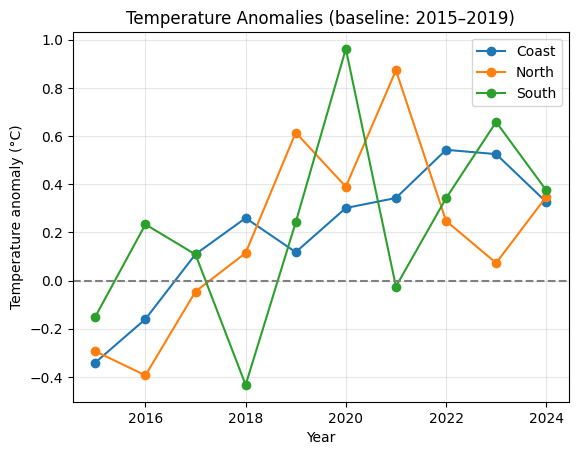

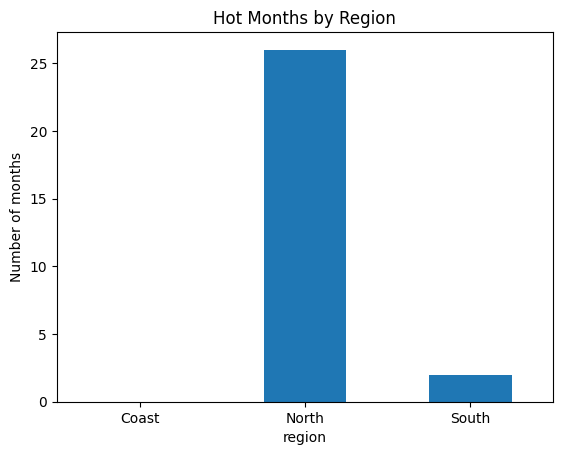

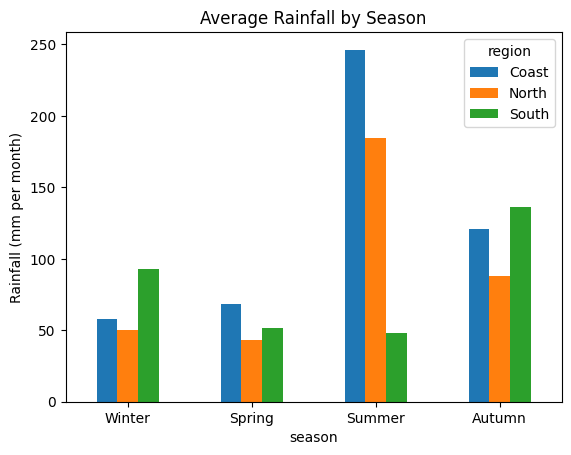

In [7]:
# Chart 1: Annual average temperature anomaly
annual_anomaly = df.groupby(['region', 'year'])['temp_anomaly'].mean().reset_index()
for region, group in annual_anomaly.groupby('region'):
    plt.plot(group['year'], group['temp_anomaly'], marker='o', label=region)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Year')
plt.ylabel('Temperature anomaly (°C)')
plt.title('Temperature Anomalies (baseline: 2015–2019)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('temperature_anomaly.png', bbox_inches='tight')
plt.show()

# Chart 2: Hot months per region
summary['hot_months'].plot(kind='bar', title='Hot Months by Region')
plt.ylabel('Number of months')
plt.xticks(rotation=0)
plt.savefig('hot_months.png', bbox_inches='tight')
plt.show()

# Chart 3: Average rainfall by season and region
rain_chart = df.groupby(['season', 'region'])['rainfall_mm'].mean().unstack()
rain_chart = rain_chart.reindex(['Winter', 'Spring', 'Summer', 'Autumn'])
rain_chart.plot(kind='bar', title='Average Rainfall by Season')
plt.ylabel('Rainfall (mm per month)')
plt.xticks(rotation=0)
plt.savefig('seasonal_rainfall.png', bbox_inches='tight')
plt.show()

In [8]:
other_baseline = df[df['year'].between(2016, 2020)]
other_normal = other_baseline.groupby(['region', 'month'])['temperature_c'].mean()
df['other_anomaly'] = df['temperature_c'] - df.set_index(['region', 'month']).index.map(other_normal)

recent = df[df['year'].between(2021, 2024)]
comparison = recent.groupby('region')[['temp_anomaly', 'other_anomaly']].mean().round(2)
print('Recent average anomalies using two different baselines:')
display(comparison)

coverage = df.groupby(['region', 'year']).size().reset_index(name='months_available')
print('Region-years with incomplete coverage:')
display(coverage[coverage['months_available'] < 12])

# Trend using complete years only, for a simple coverage sensitivity check.
complete = coverage[coverage['months_available'] == 12][['region', 'year']]
complete_annual = annual.merge(complete, on=['region', 'year'])
print('Trend using complete years only (°C/year):')
for region, group in complete_annual.groupby('region'):
    slope = np.polyfit(group['year'], group['temperature_c'], 1)[0]
    print(region, ':', round(slope, 3))

Recent average anomalies using two different baselines:


,temp_anomaly,other_anomaly
region,,
Coast,0.43,0.31
North,0.39,0.25
South,0.34,0.13


Region-years with incomplete coverage:


,region,year,months_available
1,Coast,2016,11
8,Coast,2023,11
12,North,2017,11
25,South,2020,11


Trend using complete years only (°C/year):
Coast : 0.074
North : 0.074
South : 0.061


In [9]:
df.to_csv('climate_analyzed.csv', index=False)
summary.to_csv('regional_summary.csv')
seasonal.to_csv('seasonal_summary.csv')
coverage.to_csv('data_coverage.csv', index=False)

print('Saved: climate_analyzed.csv, regional_summary.csv, seasonal_summary.csv, data_coverage.csv')
print('Saved charts: temperature_anomaly.png, hot_months.png, seasonal_rainfall.png')

Saved: climate_analyzed.csv, regional_summary.csv, seasonal_summary.csv, data_coverage.csv
Saved charts: temperature_anomaly.png, hot_months.png, seasonal_rainfall.png
